In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

In [2]:
# ---------- 1. Load data ----------
index = pd.read_csv('/Users/jahaankachwala/Downloads/Projects /Federal /index_cleaned.csv')
federal = pd.read_csv('/Users/jahaankachwala/Downloads/Projects /Federal /Federal_Funds_Target_Range_cleaned.csv')

index['Date'] = pd.to_datetime(index['Date'])
federal['observation_date'] = pd.to_datetime(federal['observation_date'])

In [3]:
# ---------- 2. Basic checks ----------
print('Index shape:', index.shape, '| Federal shape:', federal.shape)
print('\nMissing values (index):\n', index.isna().sum())
print('\nSummary (index):\n', index.describe().T.round(2))
print('\nIndex dates:', index['Date'].min().date(), 'to', index['Date'].max().date())
print('Federal dates:', federal['observation_date'].min().date(), 'to', federal['observation_date'].max().date())

Index shape: (904, 11) | Federal shape: (3649, 4)

Missing values (index):
 Year                              0
Month                             0
Day                               0
Federal Funds Target Rate       442
Federal Funds Upper Target      801
Federal Funds Lower Target      801
Effective Federal Funds Rate    152
Real GDP (Percent Change)       654
Unemployment Rate               152
Inflation Rate                  194
Date                              0
dtype: int64

Summary (index):
                               count                           mean  \
Year                          904.0                     1986.68031   
Month                         904.0                       6.598451   
Day                           904.0                       3.598451   
Federal Funds Target Rate     462.0                       5.658415   
Federal Funds Upper Target    103.0                       0.308252   
Federal Funds Lower Target    103.0                       0.058252   
Effect

In [4]:
# ---------- 3. Correlation ----------
target = 'Effective Federal Funds Rate'
features = ['Inflation Rate', 'Unemployment Rate']  # Real GDP dropped: too sparse and not significant
cols = [target, 'Real GDP (Percent Change)'] + features
print('\nCorrelation matrix:\n', index[cols].corr().round(2))


Correlation matrix:
                               Effective Federal Funds Rate  \
Effective Federal Funds Rate                          1.00   
Real GDP (Percent Change)                            -0.10   
Inflation Rate                                        0.78   
Unemployment Rate                                     0.04   

                              Real GDP (Percent Change)  Inflation Rate  \
Effective Federal Funds Rate                      -0.10            0.78   
Real GDP (Percent Change)                          1.00           -0.18   
Inflation Rate                                    -0.18            1.00   
Unemployment Rate                                 -0.03            0.21   

                              Unemployment Rate  
Effective Federal Funds Rate               0.04  
Real GDP (Percent Change)                 -0.03  
Inflation Rate                             0.21  
Unemployment Rate                          1.00  


In [5]:
# ---------- 4. Model data (drop missing rows) ----------
data = index[['Date', target] + features].dropna().reset_index(drop=True)
print('\nRows used for modelling:', len(data))


Rows used for modelling: 710


In [6]:
# ---------- 5. Time-ordered train/test split ----------
split = int(len(data) * 0.8)
train, test = data.iloc[:split], data.iloc[split:]
X_train, y_train = train[features], train[target]
X_test, y_test = test[features], test[target]

In [7]:
# ---------- 6. Fit and evaluate models ----------
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=0),
}
preds = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    preds[name] = model.predict(X_test)
    print(f"\n{name}")
    print('  R2 :', round(r2_score(y_test, preds[name]), 3))
    print('  MAE:', round(mean_absolute_error(y_test, preds[name]), 3))


Linear Regression
  R2 : -1.167
  MAE: 2.527

Random Forest
  R2 : -0.503
  MAE: 1.947


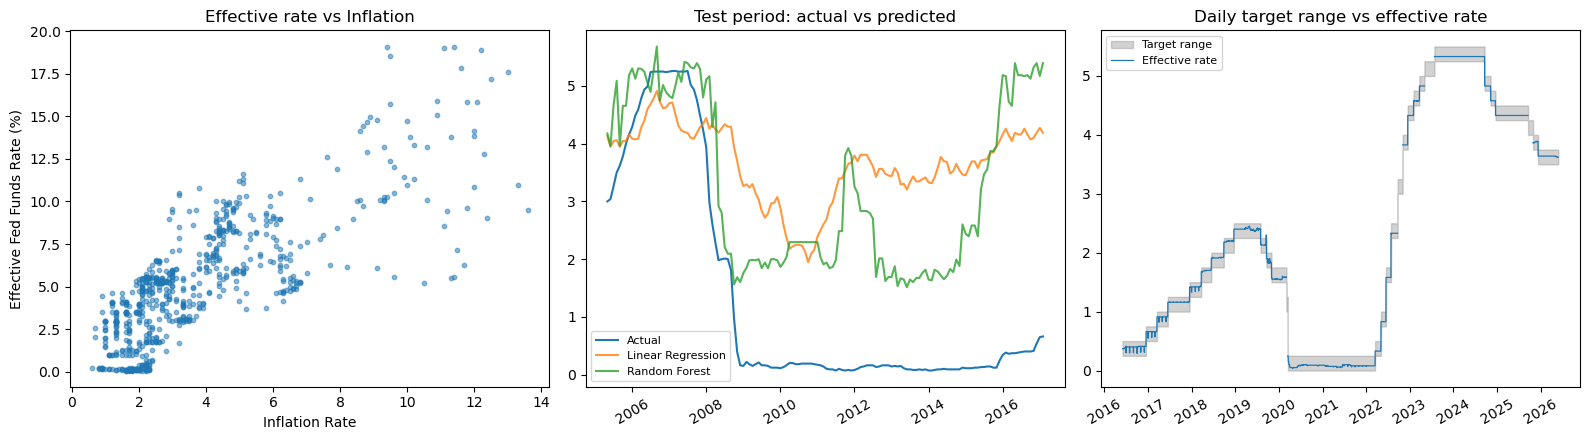

In [8]:
# ---------- 7. Plots ----------
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

ax[0].scatter(data['Inflation Rate'], data[target], s=10, alpha=0.5)
ax[0].set_xlabel('Inflation Rate')
ax[0].set_ylabel('Effective Fed Funds Rate (%)')
ax[0].set_title('Effective rate vs Inflation')

ax[1].plot(test['Date'], y_test.values, label='Actual')
for name, p in preds.items():
    ax[1].plot(test['Date'], p, label=name, alpha=0.8)
ax[1].set_title('Test period: actual vs predicted')
ax[1].legend(fontsize=8)
ax[1].tick_params(axis='x', rotation=30)

ax[2].fill_between(federal['observation_date'], federal['DFEDTARL'], federal['DFEDTARU'],
                   color='grey', alpha=0.35, label='Target range')
ax[2].plot(federal['observation_date'], federal['DFF'], lw=0.9, label='Effective rate')
ax[2].set_title('Daily target range vs effective rate')
ax[2].legend(fontsize=8)
ax[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('federal_analysis.png', dpi=110)
plt.show()

In [9]:
# ---------- 8. Peak and low checks (for the claims) ----------
peak = index.loc[index[target].idxmax(), ['Date', target]]
print('\nMonthly file peak:\n', peak)
low_daily = federal.loc[federal['DFF'].idxmin(), ['observation_date', 'DFF']]
high_daily = federal.loc[federal['DFEDTARU'].idxmax(), ['observation_date', 'DFEDTARU']]
print('\nDaily file low:\n', low_daily)
print('\nDaily file high:\n', high_daily)


Monthly file peak:
 Date                            1981-06-01 00:00:00
Effective Federal Funds Rate                   19.1
Name: 323, dtype: object

Daily file low:
 observation_date    2020-04-23 00:00:00
DFF                                0.04
Name: 1422, dtype: object

Daily file high:
 observation_date    2023-07-27 00:00:00
DFEDTARU                            5.5
Name: 2612, dtype: object


In [10]:
#Average effective rate by decade
index['Decade'] = (index['Date'].dt.year // 10) * 10
print(index.groupby('Decade')[['Effective Federal Funds Rate',
                               'Inflation Rate',
                               'Unemployment Rate']].mean().round(2))

        Effective Federal Funds Rate  Inflation Rate  Unemployment Rate
Decade                                                                 
1950                            2.36            2.14               5.07
1960                            4.18            2.46               4.78
1970                            7.10            6.48               6.22
1980                            9.97            6.08               7.27
1990                            5.15            3.22               5.76
2000                            2.96            2.16               5.54
2010                            0.17            1.76               7.12


In [11]:
#How often the effective rate sits inside the target range
valid = federal.dropna(subset=['DFF'])
inside = (valid['DFF'] >= valid['DFEDTARL']) & (valid['DFF'] <= valid['DFEDTARU'])
print('Days with an effective rate:', len(valid))
print('Share inside the target range:', round(inside.mean() * 100, 1), '%')

Days with an effective rate: 3439
Share inside the target range: 99.9 %


Days with an effective rate: 3439
Share inside the target range: 99.9 %


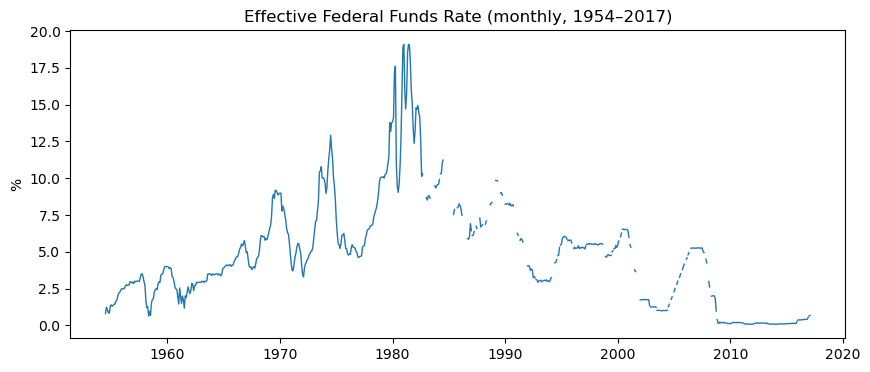

In [14]:
#Plot the effective rate over time
valid = federal.dropna(subset=['DFF'])
inside = (valid['DFF'] >= valid['DFEDTARL']) & (valid['DFF'] <= valid['DFEDTARU'])
print('Days with an effective rate:', len(valid))
print('Share inside the target range:', round(inside.mean() * 100, 1), '%')

plt.figure(figsize=(10, 4))
plt.plot(index['Date'], index['Effective Federal Funds Rate'], lw=1)
plt.title('Effective Federal Funds Rate (monthly, 1954–2017)')
plt.ylabel('%')
plt.show()